In [1]:
!pip install -q tensorflow scikit-learn pandas matplotlib seaborn

In [2]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download(
    "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews"
)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Path to dataset files: /kaggle/input/imdb-dataset-of-50k-movie-reviews


In [3]:
import os
import pandas as pd

file_path = os.path.join(path, "IMDB Dataset.csv")
df = pd.read_csv(file_path)

print(df.shape)
display(df.head())

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
df = df.drop_duplicates(subset="review")

positive = df[df["sentiment"] == "positive"].sample(
    n=2500, random_state=42
)
negative = df[df["sentiment"] == "negative"].sample(
    n=2500, random_state=42
)

df = pd.concat([positive, negative]).sample(
    frac=1, random_state=42
).reset_index(drop=True)

print("Total reviews:", len(df))
print(df["sentiment"].value_counts())

Total reviews: 5000
sentiment
positive    2500
negative    2500
Name: count, dtype: int64


In [5]:
import re

def clean_text(text):
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip().lower()

df["review"] = df["review"].apply(clean_text)
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(df[["review", "sentiment", "label"]].head())
print("Cleaning completed!")

                                              review sentiment  label
0  asterix and the vikings is the first animated ...  positive      1
1  mirrormask was a terribly disappointing film f...  negative      0
2  this hit film has not aged well but frankly it...  negative      0
3  as other reviews have stated there are a few m...  positive      1
4  this is one of the few movies i watched twice ...  positive      1
Cleaning completed!


In [6]:
from sklearn.model_selection import train_test_split

X = df["review"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 3500
Validation: 750
Testing: 750


In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train = pad_sequences(
    tokenizer.texts_to_sequences(X_train),
    maxlen=200, padding="post", truncating="post"
)

X_val = pad_sequences(
    tokenizer.texts_to_sequences(X_val),
    maxlen=200, padding="post", truncating="post"
)

X_test = pad_sequences(
    tokenizer.texts_to_sequences(X_test),
    maxlen=200, padding="post", truncating="post"
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (3500, 200)
Validation shape: (750, 200)
Testing shape: (750, 200)


In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Recreate text data
X = df["review"].astype(str)
y = df["label"].values

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train.tolist())

X_train = pad_sequences(tokenizer.texts_to_sequences(X_train.tolist()),
                        maxlen=200, padding="post")
X_val = pad_sequences(tokenizer.texts_to_sequences(X_val.tolist()),
                      maxlen=200, padding="post")
X_test = pad_sequences(tokenizer.texts_to_sequences(X_test.tolist()),
                       maxlen=200, padding="post")

print(X_train.shape, X_val.shape, X_test.shape)

(3500, 200) (750, 200) (750, 200)


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(10000, 64),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 15s 130ms/step - accuracy: 0.4983 - loss: 0.6932 - val_accuracy: 0.5240 - val_loss: 0.6922
Epoch 2/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 151ms/step - accuracy: 0.5717 - loss: 0.6861 - val_accuracy: 0.5747 - val_loss: 0.6727
Epoch 3/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 147ms/step - accuracy: 0.5917 - loss: 0.6480 - val_accuracy: 0.5453 - val_loss: 0.6914
Epoch 4/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - accuracy: 0.6429 - loss: 0.5755 - val_accuracy: 0.5693 - val_loss: 0.6616
Epoch 5/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 148ms/step - accuracy: 0.6731 - loss: 0.5254 - val_accuracy: 0.5853 - val_loss: 0.6665


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))

Accuracy : 0.6
Precision: 0.8712871287128713
Recall   : 0.23466666666666666
F1 Score : 0.3697478991596639


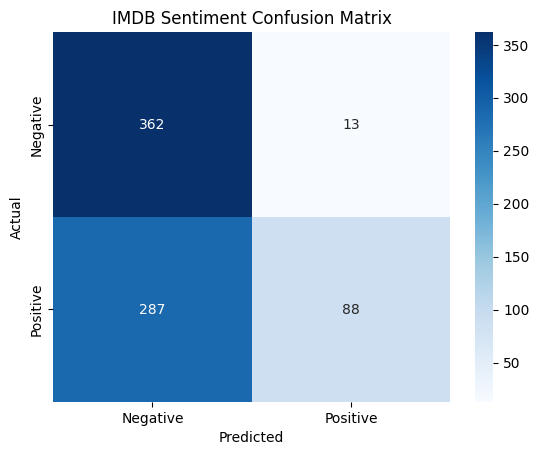

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("IMDB Sentiment Confusion Matrix")
plt.show()

In [13]:
reviews = [
    "This movie was amazing and I loved it.",
    "The film was boring and very disappointing.",
    "Excellent acting and a wonderful story.",
    "Worst movie ever, waste of time.",
    "The movie was okay but nothing special."
]

seq = tokenizer.texts_to_sequences(reviews)
pad = pad_sequences(seq, maxlen=200, padding="post")

predictions = model.predict(pad, verbose=0)

for review, pred in zip(reviews, predictions):
    sentiment = "Positive" if pred[0] >= 0.5 else "Negative"
    print("Review:", review)
    print("Sentiment:", sentiment)
    print()

Review: This movie was amazing and I loved it.
Sentiment: Negative

Review: The film was boring and very disappointing.
Sentiment: Negative

Review: Excellent acting and a wonderful story.
Sentiment: Negative

Review: Worst movie ever, waste of time.
Sentiment: Negative

Review: The movie was okay but nothing special.
Sentiment: Negative



In [17]:
reviews = [
    "This movie was amazing and I loved it.",
    "The film was boring and disappointing.",
    "Excellent acting and wonderful story.",
    "Worst movie ever, waste of time.",
    "The movie was okay but nothing special."
]

seq = tokenizer.texts_to_sequences(reviews)
padded = pad_sequences(seq, maxlen=200, padding="post")

predictions = model.predict(padded, verbose=0)

for review, pred in zip(reviews, predictions):
    sentiment = "Positive" if pred[0] >= 0.5 else "Negative"
    print(review, "->", sentiment)

This movie was amazing and I loved it. -> Negative
The film was boring and disappointing. -> Negative
Excellent acting and wonderful story. -> Negative
Worst movie ever, waste of time. -> Negative
The movie was okay but nothing special. -> Negative


In [18]:
for review, pred in zip(reviews, predictions):
    print(review)
    print("Positive probability:", round(float(pred[0]), 4))
    print()

This movie was amazing and I loved it.
Positive probability: 0.4764

The film was boring and disappointing.
Positive probability: 0.4764

Excellent acting and wonderful story.
Positive probability: 0.4764

Worst movie ever, waste of time.
Positive probability: 0.4764

The movie was okay but nothing special.
Positive probability: 0.4764



In [19]:
model = Sequential([
    Embedding(10000, 64, mask_zero=True),
    LSTM(32),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 133ms/step - accuracy: 0.5780 - loss: 0.6787 - val_accuracy: 0.6920 - val_loss: 0.5852
Epoch 2/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 143ms/step - accuracy: 0.8129 - loss: 0.4402 - val_accuracy: 0.7920 - val_loss: 0.4581
Epoch 3/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 10s 141ms/step - accuracy: 0.9183 - loss: 0.2329 - val_accuracy: 0.8400 - val_loss: 0.4228
Epoch 4/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 120ms/step - accuracy: 0.9574 - loss: 0.1434 - val_accuracy: 0.8400 - val_loss: 0.4039
Epoch 5/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 143ms/step - accuracy: 0.9766 - loss: 0.0817 - val_accuracy: 0.8507 - val_loss: 0.4334


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

Accuracy : 0.8
Precision: 0.844
Recall   : 0.736
F1 Score : 0.7863


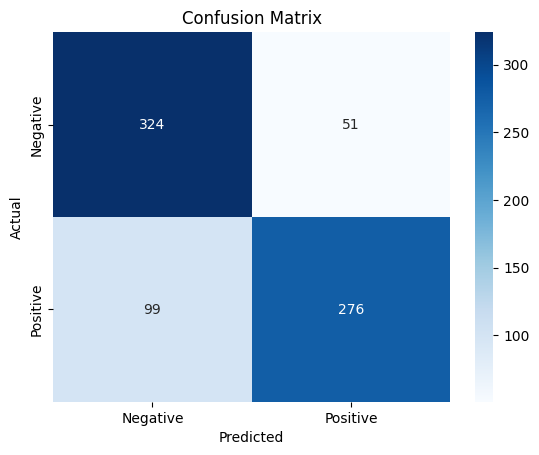

In [21]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [22]:
reviews = [
    "This movie was amazing and I loved it.",
    "The film was boring and disappointing.",
    "Excellent acting and wonderful story.",
    "Worst movie ever, waste of time.",
    "The movie was okay but nothing special."
]

seq = tokenizer.texts_to_sequences(reviews)
padded = pad_sequences(seq, maxlen=200, padding="post")

predictions = model.predict(padded, verbose=0)

for review, pred in zip(reviews, predictions):
    sentiment = "Positive" if pred[0] >= 0.5 else "Negative"
    print("Review:", review)
    print("Sentiment:", sentiment)
    print()

Review: This movie was amazing and I loved it.
Sentiment: Positive

Review: The film was boring and disappointing.
Sentiment: Negative

Review: Excellent acting and wonderful story.
Sentiment: Positive

Review: Worst movie ever, waste of time.
Sentiment: Negative

Review: The movie was okay but nothing special.
Sentiment: Negative

